In [8]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

In [9]:
from google.colab import files
uploaded = files.upload()

Saving archive.zip to archive (2).zip


In [22]:
import pandas as pd

df = pd.read_csv("synthetic_traffic_benchmark_200k.csv")

print("Dataset shape:", df.shape)
print(df.columns.tolist())
display(df.head())

Dataset shape: (200000, 29)
['Record_ID', 'Timestamp', 'Date', 'Hour', 'Month', 'Day_of_Week', 'Time_of_Day', 'Is_Holiday', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Speed_Limit_kmh', 'Weather', 'Road_Condition', 'Visibility_m', 'Congestion_Index', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Baseline_Expected_Response_Time_min', 'Accident_Occurred', 'Collision_Type', 'Vehicles_Involved', 'Accident_Severity', 'Dispatch_Priority', 'Actual_Response_Time_min', 'Road_Closure_Duration_min']


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0000000,2024-03-14 17:35:06.841829282,2024-03-14,17,3,Thursday,Evening Peak,0,Urban,Interstate,...,7.2,49.0,6.2,0,NaN,0,No Accident,NaN,0.0,0.0
1,REC_0000001,2023-05-25 08:10:56.398060108,2023-05-25,8,5,Thursday,Morning Peak,0,Suburban,Interstate,...,9.4,70.1,15.0,0,NaN,0,No Accident,NaN,0.0,0.0
2,REC_0000002,2023-11-07 08:25:17.721608262,2023-11-07,8,11,Tuesday,Morning Peak,0,Suburban,Interstate,...,2.9,71.9,14.6,0,NaN,0,No Accident,NaN,0.0,0.0
3,REC_0000003,2024-07-24 09:30:00.947374674,2024-07-24,9,7,Wednesday,Morning Peak,0,Suburban,Collector,...,4.4,58.7,13.2,0,NaN,0,No Accident,NaN,0.0,0.0
4,REC_0000004,2024-04-03 09:34:07.316651267,2024-04-03,9,4,Wednesday,Morning Peak,0,Urban,Local,...,1.8,25.4,7.8,0,NaN,0,No Accident,NaN,0.0,0.0


In [23]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (200000, 29)

Missing Values:
Record_ID                                   0
Timestamp                                   0
Date                                        0
Hour                                        0
Month                                       0
Day_of_Week                                 0
Time_of_Day                                 0
Is_Holiday                                  0
Area_Type                                   0
Road_Type                                   0
Intersection_Type                       68519
Speed_Limit_kmh                             0
Weather                                     0
Road_Condition                              0
Visibility_m                             5093
Congestion_Index                            0
Vehicle_Type                                0
Driver_Age                                  0
Driver_Experience_yrs                    3996
Vehicle_Age_yrs                             0
Recorded_Speed_kmh                 

In [24]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing numerical values with median
num_cols = df.select_dtypes(include="number").columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
cat_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in cat_cols:
    mode = df[col].mode()
    if not mode.empty:
        df[col] = df[col].fillna(mode.iloc[0])
    else:
        df[col] = df[col].fillna("Unknown")

print("Missing values handled!")
print(df.isnull().sum())
display(df.head())

Missing values handled!
Record_ID                              0
Timestamp                              0
Date                                   0
Hour                                   0
Month                                  0
Day_of_Week                            0
Time_of_Day                            0
Is_Holiday                             0
Area_Type                              0
Road_Type                              0
Intersection_Type                      0
Speed_Limit_kmh                        0
Weather                                0
Road_Condition                         0
Visibility_m                           0
Congestion_Index                       0
Vehicle_Type                           0
Driver_Age                             0
Driver_Experience_yrs                  0
Vehicle_Age_yrs                        0
Recorded_Speed_kmh                     0
Baseline_Expected_Response_Time_min    0
Accident_Occurred                      0
Collision_Type                   

,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0000000,2024-03-14 17:35:06.841829282,2024-03-14,17,3,Thursday,Evening Peak,0,Urban,Interstate,...,7.2,49.0,6.2,0,Rear-End,0,No Accident,Standard,0.0,0.0
1,REC_0000001,2023-05-25 08:10:56.398060108,2023-05-25,8,5,Thursday,Morning Peak,0,Suburban,Interstate,...,9.4,70.1,15.0,0,Rear-End,0,No Accident,Standard,0.0,0.0
2,REC_0000002,2023-11-07 08:25:17.721608262,2023-11-07,8,11,Tuesday,Morning Peak,0,Suburban,Interstate,...,2.9,71.9,14.6,0,Rear-End,0,No Accident,Standard,0.0,0.0
3,REC_0000003,2024-07-24 09:30:00.947374674,2024-07-24,9,7,Wednesday,Morning Peak,0,Suburban,Collector,...,4.4,58.7,13.2,0,Rear-End,0,No Accident,Standard,0.0,0.0
4,REC_0000004,2024-04-03 09:34:07.316651267,2024-04-03,9,4,Wednesday,Morning Peak,0,Urban,Local,...,1.8,25.4,7.8,0,Rear-End,0,No Accident,Standard,0.0,0.0


In [25]:
print("Available columns:")
for col in df.columns:
    print(col)

Available columns:
Record_ID
Timestamp
Date
Hour
Month
Day_of_Week
Time_of_Day
Is_Holiday
Area_Type
Road_Type
Intersection_Type
Speed_Limit_kmh
Weather
Road_Condition
Visibility_m
Congestion_Index
Vehicle_Type
Driver_Age
Driver_Experience_yrs
Vehicle_Age_yrs
Recorded_Speed_kmh
Baseline_Expected_Response_Time_min
Accident_Occurred
Collision_Type
Vehicles_Involved
Accident_Severity
Dispatch_Priority
Actual_Response_Time_min
Road_Closure_Duration_min


In [26]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# Identify categorical columns
cat_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Convert categorical values into numbers
label_encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le

print("Categorical encoding completed!")
display(df.head())

Categorical encoding completed!


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,0,109344,803,17,3,4,0,0,2,2,...,7.2,49.0,6.2,0,1,0,3,2,0.0,0.0
1,1,69063,509,8,5,4,2,0,1,2,...,9.4,70.1,15.0,0,1,0,3,2,0.0,0.0
2,2,91815,675,8,11,5,2,0,1,2,...,2.9,71.9,14.6,0,1,0,3,2,0.0,0.0
3,3,127275,935,9,7,6,2,0,1,1,...,4.4,58.7,13.2,0,1,0,3,2,0.0,0.0
4,4,112011,823,9,4,6,2,0,2,3,...,1.8,25.4,7.8,0,1,0,3,2,0.0,0.0


In [27]:
# Select numerical columns
num_cols = df.select_dtypes(include=["number"]).columns.tolist()

# Normalize values between 0 and 1
scaler = MinMaxScaler()

df[num_cols] = scaler.fit_transform(df[num_cols])

print("Normalization completed!")
display(df.head())

Normalization completed!


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,0.000000,0.548360,0.550000,0.739130,0.181818,0.666667,0.000000,0.0,1.0,0.666667,...,0.240000,0.049049,0.120301,0.0,0.333333,0.0,0.75,1.0,0.0,0.0
1,0.000005,0.346351,0.348630,0.347826,0.363636,0.666667,0.666667,0.0,0.5,0.666667,...,0.313333,0.070170,0.451128,0.0,0.333333,0.0,0.75,1.0,0.0,0.0
2,0.000010,0.460452,0.462329,0.347826,0.909091,0.833333,0.666667,0.0,0.5,0.666667,...,0.096667,0.071972,0.436090,0.0,0.333333,0.0,0.75,1.0,0.0,0.0
3,0.000015,0.638283,0.640411,0.391304,0.545455,1.000000,0.666667,0.0,0.5,0.333333,...,0.146667,0.058759,0.383459,0.0,0.333333,0.0,0.75,1.0,0.0,0.0
4,0.000020,0.561735,0.563699,0.391304,0.272727,1.000000,0.666667,0.0,1.0,1.000000,...,0.060000,0.025425,0.180451,0.0,0.333333,0.0,0.75,1.0,0.0,0.0


In [28]:
print("Columns:", df.columns.tolist())
display(df.head())

Columns: ['Record_ID', 'Timestamp', 'Date', 'Hour', 'Month', 'Day_of_Week', 'Time_of_Day', 'Is_Holiday', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Speed_Limit_kmh', 'Weather', 'Road_Condition', 'Visibility_m', 'Congestion_Index', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Baseline_Expected_Response_Time_min', 'Accident_Occurred', 'Collision_Type', 'Vehicles_Involved', 'Accident_Severity', 'Dispatch_Priority', 'Actual_Response_Time_min', 'Road_Closure_Duration_min']


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,0.000000,0.548360,0.550000,0.739130,0.181818,0.666667,0.000000,0.0,1.0,0.666667,...,0.240000,0.049049,0.120301,0.0,0.333333,0.0,0.75,1.0,0.0,0.0
1,0.000005,0.346351,0.348630,0.347826,0.363636,0.666667,0.666667,0.0,0.5,0.666667,...,0.313333,0.070170,0.451128,0.0,0.333333,0.0,0.75,1.0,0.0,0.0
2,0.000010,0.460452,0.462329,0.347826,0.909091,0.833333,0.666667,0.0,0.5,0.666667,...,0.096667,0.071972,0.436090,0.0,0.333333,0.0,0.75,1.0,0.0,0.0
3,0.000015,0.638283,0.640411,0.391304,0.545455,1.000000,0.666667,0.0,0.5,0.333333,...,0.146667,0.058759,0.383459,0.0,0.333333,0.0,0.75,1.0,0.0,0.0
4,0.000020,0.561735,0.563699,0.391304,0.272727,1.000000,0.666667,0.0,1.0,1.000000,...,0.060000,0.025425,0.180451,0.0,0.333333,0.0,0.75,1.0,0.0,0.0


In [29]:
import pandas as pd
import numpy as np

# Load original dataset again
df = pd.read_csv("synthetic_traffic_benchmark_200k.csv")

print("Columns:", df.columns.tolist())
display(df.head())

Columns: ['Record_ID', 'Timestamp', 'Date', 'Hour', 'Month', 'Day_of_Week', 'Time_of_Day', 'Is_Holiday', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Speed_Limit_kmh', 'Weather', 'Road_Condition', 'Visibility_m', 'Congestion_Index', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Baseline_Expected_Response_Time_min', 'Accident_Occurred', 'Collision_Type', 'Vehicles_Involved', 'Accident_Severity', 'Dispatch_Priority', 'Actual_Response_Time_min', 'Road_Closure_Duration_min']


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0000000,2024-03-14 17:35:06.841829282,2024-03-14,17,3,Thursday,Evening Peak,0,Urban,Interstate,...,7.2,49.0,6.2,0,NaN,0,No Accident,NaN,0.0,0.0
1,REC_0000001,2023-05-25 08:10:56.398060108,2023-05-25,8,5,Thursday,Morning Peak,0,Suburban,Interstate,...,9.4,70.1,15.0,0,NaN,0,No Accident,NaN,0.0,0.0
2,REC_0000002,2023-11-07 08:25:17.721608262,2023-11-07,8,11,Tuesday,Morning Peak,0,Suburban,Interstate,...,2.9,71.9,14.6,0,NaN,0,No Accident,NaN,0.0,0.0
3,REC_0000003,2024-07-24 09:30:00.947374674,2024-07-24,9,7,Wednesday,Morning Peak,0,Suburban,Collector,...,4.4,58.7,13.2,0,NaN,0,No Accident,NaN,0.0,0.0
4,REC_0000004,2024-04-03 09:34:07.316651267,2024-04-03,9,4,Wednesday,Morning Peak,0,Urban,Local,...,1.8,25.4,7.8,0,NaN,0,No Accident,NaN,0.0,0.0


In [30]:
# Automatically detect timestamp column
time_candidates = [
    "timestamp", "datetime", "date_time",
    "event_time", "date", "time"
]

congestion_candidates = [
    "congestion", "congestion_level",
    "congestion_index", "traffic_congestion",
    "congestion_value", "congestion_score"
]

def find_column(candidates, columns):
    col_map = {
        str(c).lower().replace(" ", "_").replace("-", "_"): c
        for c in columns
    }
    for name in candidates:
        if name in col_map:
            return col_map[name]
    return None

time_col = find_column(time_candidates, df.columns)
congestion_col = find_column(congestion_candidates, df.columns)

print("Timestamp column:", time_col)
print("Congestion column:", congestion_col)

Timestamp column: Timestamp
Congestion column: Congestion_Index


In [31]:
if time_col is None or congestion_col is None:
    raise ValueError("Set time_col and congestion_col using the actual CSV column names.")

df[time_col] = pd.to_datetime(df[time_col], errors="coerce")
df[congestion_col] = pd.to_numeric(
    df[congestion_col], errors="coerce"
)

df = df.dropna(subset=[time_col, congestion_col])
df = df.sort_values(time_col)

# Group traffic data by hour
hourly_df = (
    df.set_index(time_col)[congestion_col]
    .resample("h")
    .mean()
    .to_frame(name="congestion")
)

# Fill missing hourly values
hourly_df["congestion"] = (
    hourly_df["congestion"]
    .interpolate(method="time")
    .ffill()
    .bfill()
)

hourly_df = hourly_df.dropna()

print("Hourly data shape:", hourly_df.shape)
display(hourly_df.head(10))

Hourly data shape: (35064, 1)


,congestion
Timestamp,
2022-01-01 00:00:00,20.550000
2022-01-01 01:00:00,23.491667
2022-01-01 02:00:00,26.433333
2022-01-01 03:00:00,9.500000
2022-01-01 04:00:00,17.550000
2022-01-01 05:00:00,3.500000
2022-01-01 06:00:00,76.137500
2022-01-01 07:00:00,54.611111
2022-01-01 08:00:00,67.928571


In [32]:
from sklearn.preprocessing import MinMaxScaler

LOOKBACK = 6

values = hourly_df[["congestion"]].values.astype("float32")

if len(values) <= LOOKBACK:
    raise ValueError("Not enough hourly records to create sequences.")

# Chronological split: first 80% for training
split_idx = int(len(values) * 0.8)

# Fit scaler only on training data
scaler = MinMaxScaler()
scaler.fit(values[:split_idx])

scaled_values = scaler.transform(values)

X, y, target_idx = [], [], []

for i in range(LOOKBACK, len(scaled_values)):
    X.append(scaled_values[i-LOOKBACK:i])
    y.append(scaled_values[i, 0])
    target_idx.append(i)

X = np.array(X, dtype="float32")
y = np.array(y, dtype="float32")
target_idx = np.array(target_idx)

# Split by target hour
train_mask = target_idx < split_idx
test_mask = target_idx >= split_idx

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (28045, 6, 1)
y_train shape: (28045,)
X_test shape: (7013, 6, 1)
y_test shape: (7013,)


In [33]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    LSTM(64, return_sequences=True,
         input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

print("LSTM Model Summary:")
model.summary()

LSTM Model Summary:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 6, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed!")

Epoch 1/30
789/789 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.0391 - mae: 0.1564 - val_loss: 0.0292 - val_mae: 0.1300
Epoch 2/30
789/789 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0291 - mae: 0.1294 - val_loss: 0.0286 - val_mae: 0.1262
Epoch 3/30
789/789 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0278 - mae: 0.1257 - val_loss: 0.0275 - val_mae: 0.1226
Epoch 4/30
789/789 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0269 - mae: 0.1233 - val_loss: 0.0267 - val_mae: 0.1218
Epoch 5/30
789/789 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0264 - mae: 0.1218 - val_loss: 0.0262 - val_mae: 0.1209
Epoch 6/30
789/789 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0252 - mae: 0.1187 - val_loss: 0.0250 - val_mae: 0.1151
Epoch 7/30
789/789 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - loss: 0.0242 - mae: 0.1151 - val_loss: 0.0236 - val_mae: 0.1124
Epoch 8/30
789/789 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.0239 - mae: 0.1141 - val_loss: 0.0239 - val_mae: 0.1139
Epoch 9/30
789/789 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step -

In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict on unseen test sequences
y_pred_scaled = model.predict(X_test, verbose=0)

# Convert scaled values back to original congestion units
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_pred_actual = scaler.inverse_transform(
    y_pred_scaled
).flatten()

mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print("Model Evaluation Results")
print("------------------------")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

Model Evaluation Results
------------------------
MAE  : 10.5502
RMSE : 14.6134


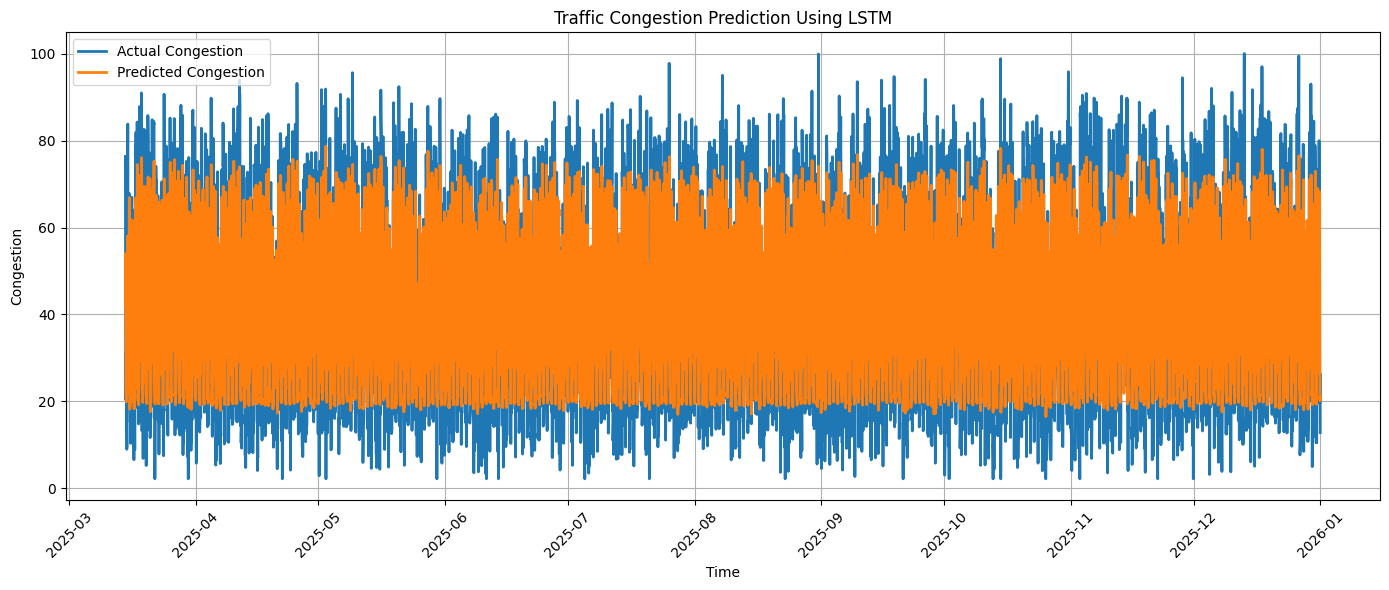

In [36]:
import matplotlib.pyplot as plt

test_times = hourly_df.index[target_idx[test_mask]]

plt.figure(figsize=(14, 6))

plt.plot(
    test_times,
    y_test_actual,
    label="Actual Congestion",
    linewidth=2
)

plt.plot(
    test_times,
    y_pred_actual,
    label="Predicted Congestion",
    linewidth=2
)

plt.title("Traffic Congestion Prediction Using LSTM")
plt.xlabel("Time")
plt.ylabel("Congestion")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
# Last six available hourly congestion values
last_six_hours = scaled_values[-LOOKBACK:]

# LSTM expects shape: (samples, time steps, features)
next_input = last_six_hours.reshape(1, LOOKBACK, 1)

# Predict the next hour
next_scaled = model.predict(next_input, verbose=0)

# Convert prediction to original units
next_congestion = scaler.inverse_transform(next_scaled)[0, 0]

next_time = hourly_df.index[-1] + pd.Timedelta(hours=1)

print("Next Hour Prediction")
print("--------------------")
print("Prediction time:", next_time)
print(f"Predicted congestion: {next_congestion:.4f}")

Next Hour Prediction
--------------------
Prediction time: 2026-01-01 00:00:00
Predicted congestion: 19.2564


In [38]:
print("======================================")
print(" TRAFFIC CONGESTION PREDICTION - LSTM")
print("======================================")

print("Dataset records:", len(df))
print("Hourly records:", len(hourly_df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nModel Evaluation")
print("----------------")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

print("\nNext Hour Prediction")
print("--------------------")
print("Prediction time:", next_time)
print(f"Congestion value: {next_congestion:.4f}")

 TRAFFIC CONGESTION PREDICTION - LSTM
Dataset records: 200000
Hourly records: 35064
Training samples: 28045
Testing samples: 7013

Model Evaluation
----------------
MAE  : 10.5502
RMSE : 14.6134

Next Hour Prediction
--------------------
Prediction time: 2026-01-01 00:00:00
Congestion value: 19.2564


In [39]:
model.save("traffic_congestion_lstm.keras")

print("LSTM model saved successfully!")

LSTM model saved successfully!


In [40]:
# Save hourly congestion data
hourly_df.to_csv("hourly_congestion.csv")

# Save actual and predicted test results
results_df = pd.DataFrame({
    "Timestamp": test_times,
    "Actual_Congestion": y_test_actual,
    "Predicted_Congestion": y_pred_actual
})

results_df.to_csv("traffic_prediction_results.csv", index=False)

# Save next-hour forecast
next_df = pd.DataFrame({
    "Prediction_Time": [next_time],
    "Predicted_Congestion": [next_congestion]
})

next_df.to_csv("next_hour_prediction.csv", index=False)

print("All output CSV files created!")
display(results_df.head())
display(next_df)

All output CSV files created!


,Timestamp,Actual_Congestion,Predicted_Congestion
0,2025-03-14 19:00:00,76.345451,53.898205
1,2025-03-14 20:00:00,48.360226,41.941231
2,2025-03-14 21:00:00,20.375000,53.340824
3,2025-03-14 22:00:00,21.500000,21.933331
4,2025-03-14 23:00:00,20.850000,21.366030


,Prediction_Time,Predicted_Congestion
0,2026-01-01,19.256411


In [42]:
from google.colab import files

files.download("traffic_congestion_lstm.keras")
files.download("hourly_congestion.csv")
files.download("traffic_prediction_results.csv")
files.download("next_hour_prediction.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>